# 3 · Train, evaluate and export the models

Uses the search result from notebook 2 (`data/models/hyperparameters.json`, or defaults if it does not exist yet) and

1. evaluates each model **leave-one-sausage-out**: train on four sausages, score on the fifth;
2. saves one model per fold (`data/models/folds/`). The demonstrator replays a sausage with the model that never saw it;
3. trains the final models on all annotated sausages (`data/models/final/`);
4. writes `manifest.json` and `metrics.json`, which the demonstrator's evaluation panel shows.

It also checks the models on the **unannotated series 2** (summer → spring): phases can only advance in time, so the
predicted phase should rise there too. A model that learned the season instead of the ripening runs backwards
(details and the comparison of feature sets: notebook 04).

`FEATURE_SET` must match the one used in notebook 2. `LIMIT_SIZE` caps the Random Forest (100 trees, depth 10). An unlimited forest on this data grows to hundreds of MB.
**Train with the same scikit-learn version the demo laptop runs**, because model files are not portable across versions.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root, so ml_core is importable
import glob
import matplotlib.pyplot as plt
import pandas as pd
from ml_core import data
from ml_core.training import (DEFAULT_AUGMENTATION, DEFAULT_CONTEXT, DEFAULT_FEATURE_SET, DEFAULT_STRIDE,
                              DEFAULT_WINDOW_SIZE, DEMO_MODELS, PROGRESSION_UNTIL, load_windows, metrics_table,
                              train_and_evaluate)

In [2]:
CONVERTED_DIR = data.CONVERTED_DIR
MODELS_DIR = data.MODELS_DIR
WINDOW_SIZE, STRIDE = DEFAULT_WINDOW_SIZE, DEFAULT_STRIDE   # uplinks per window, step between windows
CONTEXT = DEFAULT_CONTEXT           # long-term context horizons, e.g. ("24h", "7d"); compared in notebook 05
FEATURE_SET = DEFAULT_FEATURE_SET   # see FEATURE_SETS in ml_core/training.py
AUGMENT = DEFAULT_AUGMENTATION      # training-only augmentation (names: AUGMENTATIONS in ml_core/augmentation.py,
                                    # compared in notebook 04); [] = none
MODELS = list(DEMO_MODELS)          # model families to export; the dashboards show all exported models
LIMIT_SIZE = True
FOLD_MODELS = True
QUICK = False
N_JOBS = -1          # worker processes for folds (-1 = all cores); lower it if RAM runs short

In [3]:
windows = load_windows(CONVERTED_DIR, window_size=WINDOW_SIZE, stride=STRIDE, context=CONTEXT)
unannotated = None
if glob.glob(os.path.join(CONVERTED_DIR, "series_2_*.csv")):
    unannotated = load_windows(CONVERTED_DIR, "series_2_*.csv", WINDOW_SIZE, STRIDE, annotated=False,
                               classes=windows.classes, context=CONTEXT)
windows.summary()

series_1_sausage_1: 41,462 rows → 19,388 windows
series_1_sausage_2: 41,479 rows → 19,395 windows
series_1_sausage_3: 41,468 rows → 19,392 windows
series_1_sausage_4: 41,472 rows → 19,394 windows
series_1_sausage_5: 41,465 rows → 19,388 windows


series_2_sausage_1: 79,919 rows → 38,860 windows
series_2_sausage_2: 79,903 rows → 38,852 windows


series_2_sausage_3: 79,915 rows → 38,858 windows
series_2_sausage_4: 79,920 rows → 38,861 windows
series_2_sausage_5: 79,930 rows → 38,866 windows


,recording,rows,windows,from,to,Umroetung,Reifung Phase 1,Reifung Phase 2
0,series_1_sausage_1,41462,19388,2023-04-06 00:10:12.000000+00:00,2023-08-02 23:56:34.268438+00:00,5965,8116,5307
1,series_1_sausage_2,41479,19395,2023-04-06 00:11:14.000000+00:00,2023-08-02 23:43:26.013334+00:00,5969,8120,5306
2,series_1_sausage_3,41468,19392,2023-04-06 00:13:24.774014+00:00,2023-08-02 23:58:00.000000+00:00,5969,8118,5305
3,series_1_sausage_4,41472,19394,2023-04-06 00:05:37.000000+00:00,2023-08-02 23:55:25.481812+00:00,5970,8120,5304
4,series_1_sausage_5,41465,19388,2023-04-06 00:21:09.446387+00:00,2023-08-02 23:49:39.000000+00:00,5967,8117,5304


In [4]:
metrics = train_and_evaluate(windows, MODELS_DIR, FEATURE_SET, unannotated, augmentation=AUGMENT, keys=MODELS,
                             limit_size=LIMIT_SIZE, fold_models=FOLD_MODELS, quick=QUICK, n_jobs=N_JOBS)

Feature set: temperature_difference_now (lse01_conductivity, lse01_moisture, lse01_temperature_diff:now, ltcfs_temperature_diff:now)
Hyperparameters: hyperparameters.json from 2026-11-25
Augmentation (training data only): calibration_large
Augmenting the training data (calibration_large): 2 copies per sausage …



=== Logistic Regression ===  {'C': 10, 'class_weight': 'balanced', 'l1_ratio': 0, 'max_iter': 1000, 'solver': 'lbfgs'}


  without series_1_sausage_1: balanced acc 0.677 (41.7 s)


  without series_1_sausage_2: balanced acc 0.828 (41.7 s)
  without series_1_sausage_3: balanced acc 0.813 (38.5 s)


  without series_1_sausage_4: balanced acc 0.794 (44.9 s)
  without series_1_sausage_5: balanced acc 0.905 (40.9 s)


  all sausages: fitted (45.0 s)


... (12 outputs left out)

  without series_1_sausage_4: balanced acc 0.865 (107.8 s)


  without series_1_sausage_5: balanced acc 0.609 (104.0 s)


  all sausages: fitted (117.2 s)


  mean balanced acc 0.786 · 48.8 ms per prediction · 3.8 MB · series 2 phase order ρ +0.86

Wrote models, manifest.json and metrics.json to F:\_Data\Uni\MA_Project\masterproject-lorawan-demonstrator\data\models


## Results (mean ± std over the held-out sausages)

In [5]:
metrics_table(metrics)

,balanced acc,macro-F1,accuracy,ms / prediction,size (MB),fit all data (s),series 2: phase order ρ,series 2: backwards share
model,,,,,,,,
Logistic Regression,0.803 ± 0.074,0.781 ± 0.084,0.779 ± 0.089,17.03,0.01,45.0,0.831,0.060
Random Forest,0.803 ± 0.111,0.788 ± 0.129,0.789 ± 0.130,24.04,3.95,86.3,0.877,0.000
MLP (neural net),0.721 ± 0.056,0.690 ± 0.061,0.699 ± 0.066,15.93,0.13,396.3,0.811,0.073
Gradient Boosting,0.786 ± 0.140,0.753 ± 0.167,0.773 ± 0.139,48.77,3.82,117.2,0.863,0.005


In [6]:
# balanced accuracy per held-out sausage
pd.DataFrame({m["name"]: {f["held_out"]: round(f["balanced_accuracy"], 3) for f in m["folds"]}
              for m in metrics["models"].values()})

,Logistic Regression,Random Forest,MLP (neural net),Gradient Boosting
series_1_sausage_1,0.677,0.611,0.637,0.622
series_1_sausage_2,0.828,0.805,0.765,0.915
series_1_sausage_3,0.813,0.952,0.756,0.918
series_1_sausage_4,0.794,0.849,0.775,0.865
series_1_sausage_5,0.905,0.796,0.670,0.609


In [7]:
# confusion matrices, row-normalised (rows: annotation, columns: prediction)
for m in metrics["models"].values():
    cm = pd.DataFrame(m["confusion_matrix"], index=metrics["classes"], columns=metrics["classes"])
    print(m["name"])
    display((cm.div(cm.sum(axis=1), axis=0) * 100).round(1))

Logistic Regression


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,92.1,7.9,0.0
Reifung Phase 1,5.1,60.5,34.4
Reifung Phase 2,0.1,11.6,88.3


Random Forest


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,90.2,9.8,0.0
Reifung Phase 1,6.4,68.4,25.2
Reifung Phase 2,0.0,17.8,82.2


MLP (neural net)


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,88.8,11.2,0.0
Reifung Phase 1,11.4,53.4,35.2
Reifung Phase 2,0.0,25.9,74.1


Gradient Boosting


,Umroetung,Reifung Phase 1,Reifung Phase 2
Umroetung,90.7,9.3,0.0
Reifung Phase 1,9.4,66.9,23.7
Reifung Phase 2,0.0,21.9,78.1


In [8]:
# how often two models give the same label on held-out windows
pd.Series(metrics["agreement_on_held_out"]).round(3)

logreg|rf     0.810
logreg|mlp    0.857
logreg|hgb    0.815
rf|mlp        0.830
rf|hgb        0.893
mlp|hgb       0.856
dtype: float64

## Plausibility on the unannotated series 2

Predicted phase over time (smoothed over one day). Plausible: a staircase going up. A model that follows the
temperature instead goes down in autumn and winter. ρ in the table above: +1 = phases only advance.

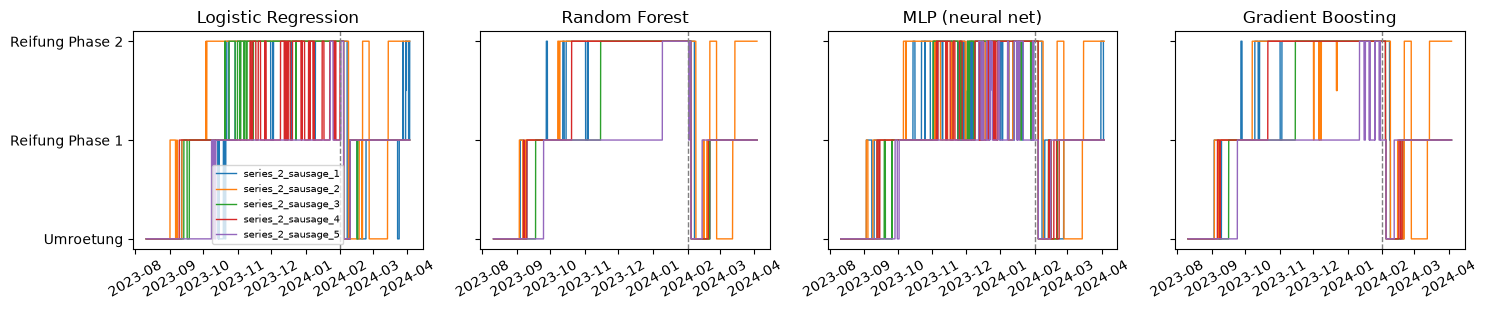

In [9]:
# the exported final models (fitted on all annotated sausages), as scored in the table above
if metrics["progressions"]:
    classes = metrics["classes"]
    fig, axes = plt.subplots(1, len(metrics["progressions"]), figsize=(15, 3.2), sharey=True, squeeze=False)
    for ax, (key, progression) in zip(axes[0], metrics["progressions"].items()):
        for rec, s in progression.items():
            ax.plot(s.index, s.values, label=rec, lw=1)
        ax.axvline(pd.Timestamp(PROGRESSION_UNTIL), color="grey", ls="--", lw=1)
        ax.set(title=metrics["models"][key]["name"], yticks=range(len(classes)), yticklabels=classes)
        ax.tick_params(axis="x", rotation=30)
    axes[0][0].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

**Next:** start the demonstrator (`scripts/start_demo.ps1`). It loads the models from `data/models/`.
Read the scores with care: all annotated sausages come from one curing run.